# Predicting volume surges

Test whether recent trading activity predicts future volume surges, and whether price and market context improve prediction. Run `build_features.ipynb` first. All times are UTC.


## 0. Setup

Load the analysis helpers and prepare the result folders.


In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

LITE_DIR = Path.cwd()
if not (LITE_DIR / "scripts" / "features.py").exists():
    LITE_DIR = LITE_DIR / "lite"

sys.path.insert(0, str(LITE_DIR / "scripts"))
import importlib
import features
import models
import evaluation

for module in (features, models, evaluation):
    importlib.reload(module)
from features import load_features, FEATURE_SETS
from models import make_logistic, make_tree
from evaluation import split_data, split_summary, evaluate

pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", None)  

## 1. Load the dataset and target

Load one observation per market and decision time. A surge means next-12-hour volume is at least $10,000 and exceeds past-24-hour volume. Predictions use completed hourly buckets sampled every four hours.


In [2]:
df = load_features()
pd.Series({
    "Prediction opportunities": len(df),
    "Markets": df.market.nunique(),
    "Surges": int(df.y.sum()),
    "Surge rate": df.y.mean(),
})

Prediction opportunities   1341469.0000
Markets                      35413.0000
Surges                       78711.0000
Surge rate                       0.0587
dtype: float64

## 2. Compare feature sets

Compare four cumulative sets: activity (A, 9 inputs), acceleration (AB, 13), price (ABC, 19), and market context (ABCD, 28). Exact formulas are in `build_features.ipynb`.


## 3. Split the data by time

Use May–August for training, September for validation, and October for testing, with 36-hour gaps before validation and test. The same markets can appear in multiple splits.


In [3]:
train, valid, test = split_data(df)
splits = split_summary(train, valid, test)
splits

,split,first_decision_time_utc,last_decision_time_utc,rows,markets,positive_rate
0,Train,2026-05-30 05:00:00+00:00,2026-08-30 09:00:00+00:00,903205,20284,0.0530
1,Validation,2026-09-01 09:00:00+00:00,2026-09-29 09:00:00+00:00,210789,10541,0.0617
2,Test,2026-10-01 01:00:00+00:00,2026-10-25 09:00:00+00:00,210529,8376,0.0789


## 4. Define metrics and a baseline

Use average precision (AP) to measure ranking quality and precision among the highest-scored 5% to measure alert precision across the evaluated period. Compare models with a simple recent-volume-acceleration baseline.

Random ranking has AP approximately equal to the positive rate. Because positive rates differ across splits, higher AP alone does not establish better generalization. The acceleration baseline is a separate comparator.


In [4]:
baseline_validation = evaluate(valid.y, valid.accel6)
pd.Series(baseline_validation, name="Acceleration baseline: validation")

AP                  0.1127
precision_at_5pct   0.1104
Name: Acceleration baseline: validation, dtype: float64

## 5. Train and validate eight models

Fit logistic regression and gradient boosting for each feature set. Logistic preprocessing is learned from training data; trees use September for early stopping. Compare training and validation scores using fixed model settings.


In [5]:
fitted_models = {}
validation_rows = []

for feature_set, columns in FEATURE_SETS.items():
    X_train = train[columns].astype("float32")
    X_valid = valid[columns].astype("float32")

    for model_name in ["Logistic regression", "Gradient boosting"]:
        if model_name == "Logistic regression":
            model = make_logistic()
            model.fit(X_train, train.y)
        else:
            model = make_tree()
            model.fit(X_train, train.y, X_val=X_valid, y_val=valid.y)

        name = f"{model_name} | {feature_set}"
        fitted_models[name] = (model, columns)
        train_score = evaluate(train.y, model.predict_proba(X_train)[:, 1])
        valid_score = evaluate(valid.y, model.predict_proba(X_valid)[:, 1])
        validation_rows.append({
            "configuration": name,
            "model": model_name,
            "feature_set": feature_set,
            "blocks": feature_set.split(":", 1)[0],
            "features": len(columns),
            "train_AP": train_score["AP"],
            "validation_AP": valid_score["AP"],
            "validation_precision_at_5pct": valid_score["precision_at_5pct"],
            "tree_iterations": getattr(model, "n_iter_", None),
        })
        print(f"Finished: {name}")

validation_results = pd.DataFrame(validation_rows)
validation_results

Finished: Logistic regression | A: Activity
Finished: Gradient boosting | A: Activity
Finished: Logistic regression | AB: Activity + acceleration
Finished: Gradient boosting | AB: Activity + acceleration
Finished: Logistic regression | ABC: Activity + acceleration + price
Finished: Gradient boosting | ABC: Activity + acceleration + price
Finished: Logistic regression | ABCD: Activity + acceleration + price + context
Finished: Gradient boosting | ABCD: Activity + acceleration + price + context


,configuration,model,feature_set,blocks,features,train_AP,validation_AP,validation_precision_at_5pct,tree_iterations
0,Logistic regression | A: Activity,Logistic regression,A: Activity,A,9,0.2127,0.2313,0.2963,NaN
1,Gradient boosting | A: Activity,Gradient boosting,A: Activity,A,9,0.4489,0.4736,0.5138,281.0000
2,Logistic regression | AB: Activity + acceleration,Logistic regression,AB: Activity + acceleration,AB,13,0.2262,0.2628,0.3282,NaN
3,Gradient boosting | AB: Activity + acceleration,Gradient boosting,AB: Activity + acceleration,AB,13,0.4610,0.5037,0.5411,182.0000
4,Logistic regression | ABC: Activity + acceleration + price,Logistic regression,ABC: Activity + acceleration + price,ABC,19,0.2595,0.3084,0.3803,NaN
5,Gradient boosting | ABC: Activity + acceleration + price,Gradient boosting,ABC: Activity + acceleration + price,ABC,19,0.4911,0.5298,0.5650,187.0000
6,Logistic regression | ABCD: Activity + acceleration + price + context,Logistic regression,ABCD: Activity + acceleration + price + context,ABCD,28,0.2903,0.3324,0.4063,NaN
7,Gradient boosting | ABCD: Activity + acceleration + price + context,Gradient boosting,ABCD: Activity + acceleration + price + context,ABCD,28,0.6627,0.7049,0.7124,274.0000


### Compare added feature blocks

Measure changes in validation performance as blocks are added from A to ABCD. Gains depend on this order and do not isolate independent feature effects.


,model,blocks,features,train_AP,validation_AP,validation_AP_gain,validation_precision_at_5pct,validation_precision_at_5pct_gain,train_minus_validation_AP
0,Logistic regression,A,9,0.2127,0.2313,NaN,0.2963,NaN,-0.0186
1,Gradient boosting,A,9,0.4489,0.4736,NaN,0.5138,NaN,-0.0247
2,Logistic regression,AB,13,0.2262,0.2628,0.0315,0.3282,0.0319,-0.0366
3,Gradient boosting,AB,13,0.4610,0.5037,0.0301,0.5411,0.0273,-0.0427
4,Logistic regression,ABC,19,0.2595,0.3084,0.0456,0.3803,0.0521,-0.0490
5,Gradient boosting,ABC,19,0.4911,0.5298,0.0261,0.5650,0.0239,-0.0387
6,Logistic regression,ABCD,28,0.2903,0.3324,0.0240,0.4063,0.0260,-0.0421
7,Gradient boosting,ABCD,28,0.6627,0.7049,0.1751,0.7124,0.1474,-0.0422


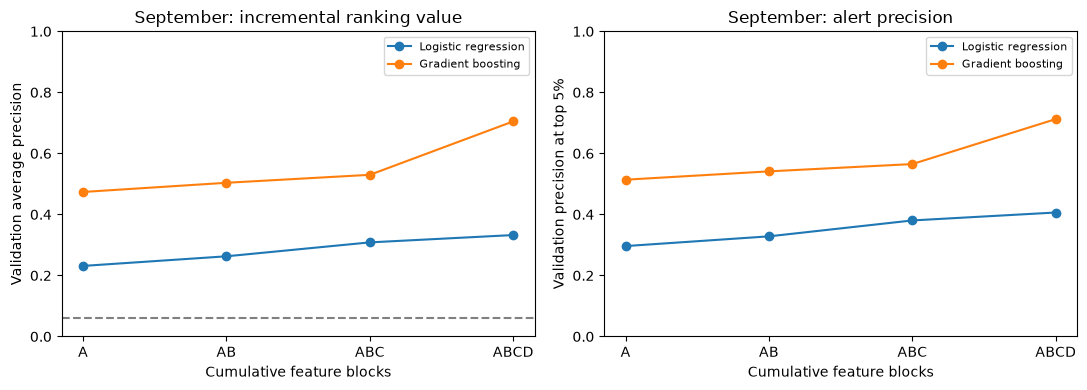

In [6]:
ablation_validation = validation_results.copy()
ablation_validation["validation_AP_gain"] = ablation_validation.groupby("model", sort=False)["validation_AP"].diff()
ablation_validation["validation_precision_at_5pct_gain"] = ablation_validation.groupby("model", sort=False)["validation_precision_at_5pct"].diff()
ablation_validation["train_minus_validation_AP"] = ablation_validation.train_AP - ablation_validation.validation_AP
display(ablation_validation[["model", "blocks", "features", "train_AP", "validation_AP",
                             "validation_AP_gain", "validation_precision_at_5pct",
                             "validation_precision_at_5pct_gain", "train_minus_validation_AP"]])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for model_name, group in ablation_validation.groupby("model", sort=False):
    axes[0].plot(group.blocks, group.validation_AP, marker="o", label=model_name)
    axes[1].plot(group.blocks, group.validation_precision_at_5pct, marker="o", label=model_name)
for ax in axes:
    ax.set(xlabel="Cumulative feature blocks", ylim=(0, 1))
    ax.legend(fontsize=8)
axes[0].axhline(valid.y.mean(), color="gray", linestyle="--", label="Random reference")
axes[0].set(ylabel="Validation average precision", title="September: incremental ranking value")
axes[1].set(ylabel="Validation precision at top 5%", title="September: alert precision")
fig.tight_layout()
plt.show()


## 6. Select the main model

Choose the configuration with the highest September AP before examining October performance.


In [7]:
best_row = validation_results.loc[validation_results.validation_AP.idxmax()]
selected_name = best_row["configuration"]
print("Selected on September AP:", selected_name)
print("Validation AP:", round(best_row["validation_AP"], 4))

Selected on September AP: Gradient boosting | ABCD: Activity + acceleration + price + context
Validation AP: 0.7049


## 7. Evaluate on the October test set

Compare all eight configurations with the baseline. Mark the model selected on validation; use test scores only for evaluation.


In [8]:
predictions = test[["market", "h", "decision_time", "y"]].copy()
predictions["Acceleration baseline"] = test.accel6.to_numpy()

for name, (model, columns) in fitted_models.items():
    predictions[name] = model.predict_proba(test[columns].astype("float32"))[:, 1]

score_columns = ["Acceleration baseline"] + list(fitted_models)
test_rows = []
for name in score_columns:
    test_rows.append({
        "configuration": name,
        "selected_on_validation": name == selected_name,
        **evaluate(predictions.y, predictions[name]),
    })

comparison = pd.DataFrame(test_rows)
print("Test surge rate:", round(predictions.y.mean(), 4))
comparison

Test surge rate: 0.0789


,configuration,selected_on_validation,AP,precision_at_5pct
0,Acceleration baseline,False,0.1421,0.1607
1,Logistic regression | A: Activity,False,0.2320,0.2646
2,Gradient boosting | A: Activity,False,0.4865,0.5732
3,Logistic regression | AB: Activity + acceleration,False,0.2555,0.3146
4,Gradient boosting | AB: Activity + acceleration,False,0.5126,0.5955
5,Logistic regression | ABC: Activity + acceleration + price,False,0.3049,0.3877
6,Gradient boosting | ABC: Activity + acceleration + price,False,0.5409,0.6237
7,Logistic regression | ABCD: Activity + acceleration + price + context,False,0.3228,0.4075
8,Gradient boosting | ABCD: Activity + acceleration + price + context,True,0.7333,0.8170


### Compare performance across splits

Summarize training, validation, and test results for each feature set using the existing fits and predictions.


In [9]:
ablation_results = ablation_validation.merge(
    comparison.rename(columns={"AP": "test_AP", "precision_at_5pct": "test_precision_at_5pct"}),
    on="configuration", how="left", validate="one_to_one",
)
ablation_results["test_AP_gain"] = ablation_results.groupby("model", sort=False)["test_AP"].diff()
ablation_results[["model", "blocks", "features", "train_AP", "validation_AP", "validation_AP_gain",
                  "test_AP", "test_AP_gain", "test_precision_at_5pct", "selected_on_validation"]]


,model,blocks,features,train_AP,validation_AP,validation_AP_gain,test_AP,test_AP_gain,test_precision_at_5pct,selected_on_validation
0,Logistic regression,A,9,0.2127,0.2313,NaN,0.2320,NaN,0.2646,False
1,Gradient boosting,A,9,0.4489,0.4736,NaN,0.4865,NaN,0.5732,False
2,Logistic regression,AB,13,0.2262,0.2628,0.0315,0.2555,0.0236,0.3146,False
3,Gradient boosting,AB,13,0.4610,0.5037,0.0301,0.5126,0.0261,0.5955,False
4,Logistic regression,ABC,19,0.2595,0.3084,0.0456,0.3049,0.0493,0.3877,False
5,Gradient boosting,ABC,19,0.4911,0.5298,0.0261,0.5409,0.0283,0.6237,False
6,Logistic regression,ABCD,28,0.2903,0.3324,0.0240,0.3228,0.0179,0.4075,False
7,Gradient boosting,ABCD,28,0.6627,0.7049,0.1751,0.7333,0.1924,0.8170,True


### Read AP alongside the random reference

For the validation-selected model, compare AP with each split's positive rate (the approximate random-ranking AP). `AP_over_random` measures the relative multiple; `AP_minus_random` measures the absolute gain.

In the current results, **AP rises from training to validation to test, while the relative multiple falls** as surges become more common. The absolute gain increases slightly. This distinction matters: higher test AP alone does not prove stronger generalization, and a lower multiple alone does not prove model deterioration. These are descriptive comparisons, not a prevalence-controlled evaluation.


In [10]:
# Compare the validation-selected model against each split's random reference.
selected_validation = validation_results.set_index("configuration").loc[selected_name]
selected_test = comparison.set_index("configuration").loc[selected_name]
ap_reference = splits[["split", "positive_rate"]].copy()
ap_by_split = {
    "Train": selected_validation["train_AP"],
    "Validation": selected_validation["validation_AP"],
    "Test": selected_test["AP"],
}
ap_reference["AP"] = ap_reference["split"].map(ap_by_split)
ap_reference = ap_reference.rename(columns={"positive_rate": "random_AP_reference"})
ap_reference["AP_over_random"] = ap_reference.AP / ap_reference.random_AP_reference
ap_reference["AP_minus_random"] = ap_reference.AP - ap_reference.random_AP_reference
display(ap_reference.round(4))


,split,random_AP_reference,AP,AP_over_random,AP_minus_random
0,Train,0.0530,0.6627,12.5158,0.6098
1,Validation,0.0617,0.7049,11.4263,0.6432
2,Test,0.0789,0.7333,9.2946,0.6544


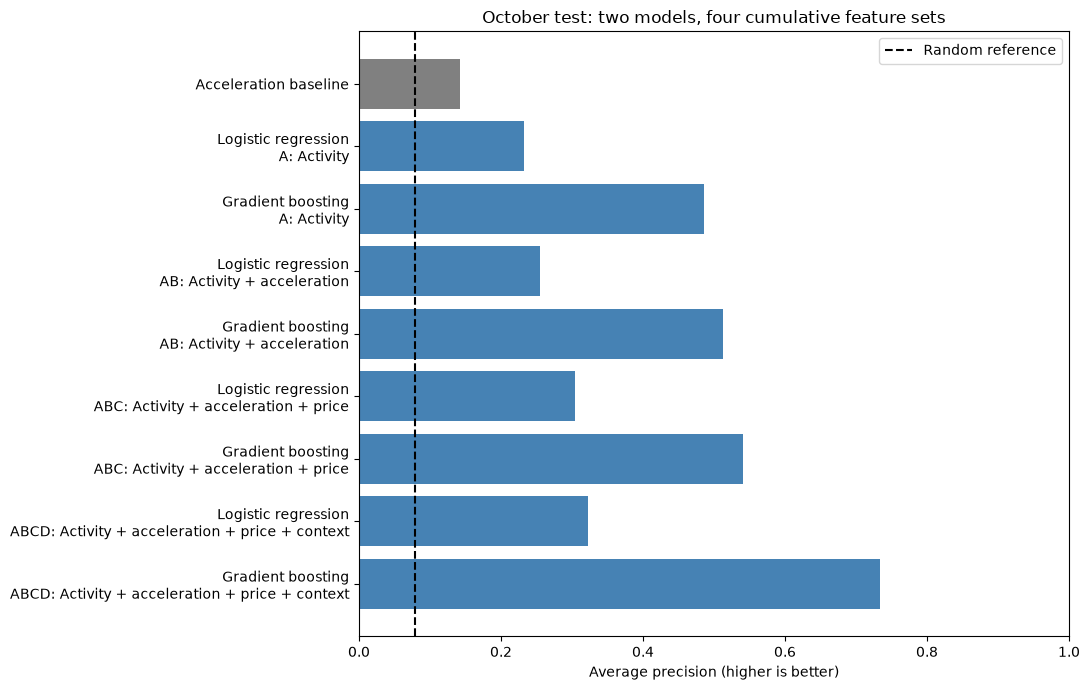

In [11]:
fig, ax = plt.subplots(figsize=(11, 7))
labels = [name.replace(" | ", "\n") for name in comparison.configuration]
ax.barh(labels, comparison.AP, color=["gray"] + ["steelblue"] * (len(comparison) - 1))
ax.axvline(predictions.y.mean(), color="black", linestyle="--", label="Random reference")
ax.invert_yaxis()
ax.set(xlabel="Average precision (higher is better)", xlim=(0, 1),
       title="October test: two models, four cumulative feature sets")
ax.legend()
fig.tight_layout()
plt.show()

## 8. Inspect precision and recall

Plot the selected model and baseline to show the trade-off between finding more surges and issuing false alerts.


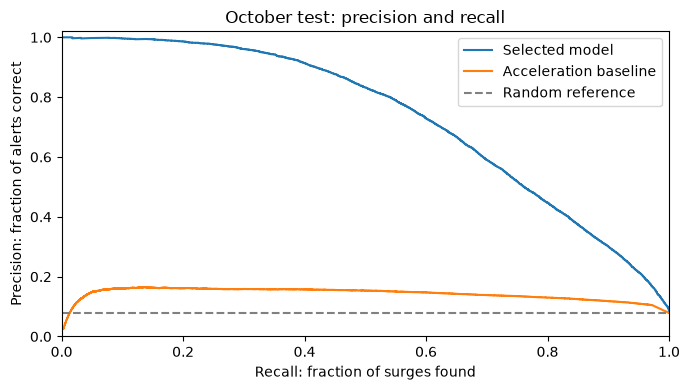

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, label in [(selected_name, "Selected model"),
                    ("Acceleration baseline", "Acceleration baseline")]:
    precision, recall, _ = precision_recall_curve(predictions.y, predictions[name])
    ax.plot(recall, precision, label=label)
ax.axhline(predictions.y.mean(), color="gray", linestyle="--", label="Random reference")
ax.set(xlabel="Recall: fraction of surges found",
       ylabel="Precision: fraction of alerts correct",
       title="October test: precision and recall", xlim=(0, 1), ylim=(0, 1.02))
ax.legend()
fig.tight_layout()
plt.show()